# PS-07: Bean Leaf Lesion Classification
**Domain:** Agriculture & Food  
**Problem Statement:** With only about 1,300 images, this is a small-data problem. Build a classifier that tells healthy bean leaves from angular leaf spot and bean rust, and show how you prevent overfitting when so few training images are available.  
**Classes:** 3 — `angular_leaf_spot` (0), `bean_rust` (1), `healthy` (2)  
**Dataset:** Beans (Makerere AI Lab) via TensorFlow Datasets (1,295 images)  

---
### Notebook Roadmap (Aligned with CBL Evaluation Rubric - 30 Marks)
1. **Reproducibility & Environment Setup:** Fixed random seeds across Python, NumPy, and TensorFlow; library version logging.
2. **Dataset Loading & Exploratory Data Analysis (EDA):** Load `beans` via `tensorflow_datasets` (with local folder fallback), inspect split sizes (1,034 train / 133 val / 128 test), plot class balance, and display sample leaves per class.
3. **Pre-processing & Data Pipeline:** Resize to `224x224`, batching, prefetching, and **in-graph Data Augmentation** (applied strictly to training data to prevent data leakage).
4. **Addressing the Specific Challenge (Small Data Overfitting):**
   - **Baseline Model (Custom CNN from Scratch):** Demonstrates rapid overfitting on 1,034 images when trained without regularization/priors.
   - **Proposed Model (Regularized Transfer Learning with MobileNetV2 + Fine-Tuning):** Combines ImageNet feature priors, Data Augmentation, Spatial Dropout (`p=0.4`), L2 Weight Decay (`1e-4`), and Early Stopping to prevent overfitting.
5. **Comprehensive Test Set Evaluation:** Single evaluation on the held-out test split reporting Accuracy, Per-Class Precision/Recall/F1, Macro F1, and Confusion Matrix.
6. **Error Analysis:** Visualizing at least 4 misclassified test images with predicted vs. true probabilities and diagnostic explanations.


## 1. Environment Setup & Reproducibility
To satisfy the reproducibility requirement of the rubric, we fix all random seeds (`SEED = 42`) and log exact package versions.


In [1]:
# Fix for Python 3.13 / Google Colab tensorflow_datasets compatibility
!pip install -q importlib_resources

import os
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
import tensorflow_datasets as tfds
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    precision_recall_fscore_support
)

# 1. Set Fixed Random Seed for Complete Reproducibility
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Log versions
print(f"TensorFlow Version : {tf.__version__}")
print(f"TFDS Version       : {tfds.__version__}")
print(f"NumPy Version      : {np.__version__}")
print(f"GPU Available      : {tf.config.list_physical_devices('GPU')}")


TensorFlow Version : 2.21.0
TFDS Version       : 4.9.10
NumPy Version      : 2.1.3
GPU Available      : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Dataset Loading & Exploratory Data Analysis (EDA)
The official **Beans** dataset from Makerere AI Lab is natively hosted in `tensorflow_datasets` (`beans`) with a standardized, non-overlapping split:
- **Train:** 1,034 images
- **Validation:** 133 images
- **Test:** 128 images
- **Total:** 1,295 images across 3 classes (`angular_leaf_spot`, `bean_rust`, `healthy`).

*(Note: If your lab system provides a local directory instead of internet access, set `USE_LOCAL_DIR = True` and point `LOCAL_DATA_DIR` to the folder path).*


In [3]:
# Automatic Download & Loading of the Official Beans Dataset (1,295 images)
# Note: The legacy storage.googleapis.com/ibeans bucket used by tfds returns HTTP 403,
# so we download the exact same official Makerere AI Lab train/validation/test ZIP archives
# from the official AI-Lab-Makerere/beans mirror.
import os
import urllib.request
import zipfile

DATA_DIR = "/content/beans_dataset"
os.makedirs(DATA_DIR, exist_ok=True)

urls = {
    "train": "https://huggingface.co/datasets/AI-Lab-Makerere/beans/resolve/main/data/train.zip",
    "validation": "https://huggingface.co/datasets/AI-Lab-Makerere/beans/resolve/main/data/validation.zip",
    "test": "https://huggingface.co/datasets/AI-Lab-Makerere/beans/resolve/main/data/test.zip"
}

for split_name, url in urls.items():
    zip_path = os.path.join(DATA_DIR, f"{split_name}.zip")
    if not os.path.exists(os.path.join(DATA_DIR, split_name)):
        print(f"Downloading official {split_name}.zip...")
        urllib.request.urlretrieve(url, zip_path)
        with zipfile.ZipFile(zip_path, 'r') as zf:
            zf.extractall(DATA_DIR)

IMG_SIZE_LOAD = (500, 500)
train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATA_DIR, 'train'), seed=SEED, image_size=IMG_SIZE_LOAD, batch_size=None, label_mode='int')
val_ds_raw = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATA_DIR, 'validation'), seed=SEED, image_size=IMG_SIZE_LOAD, batch_size=None, label_mode='int')
test_ds_raw = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATA_DIR, 'test'), seed=SEED, image_size=IMG_SIZE_LOAD, batch_size=None, label_mode='int')

class_names = train_ds_raw.class_names
num_classes = len(class_names)
print(f"\nLoaded Beans dataset successfully! Classes ({num_classes}): {class_names}")

Found 1034 files belonging to 3 classes.
Found 133 files belonging to 3 classes.
Found 128 files belonging to 3 classes.

Loaded Beans dataset successfully! Classes (3): ['angular_leaf_spot', 'bean_rust', 'healthy']


### 2.1 Class Distribution Across Splits
We verify class balance across the Training, Validation, and Test splits to check whether class imbalance exists alongside the small-data challenge.


=== Dataset Split and Class Distribution ===


,angular_leaf_spot,bean_rust,healthy,Total
Train,345,348,341,1034
Validation,44,45,44,133
Test,43,43,42,128


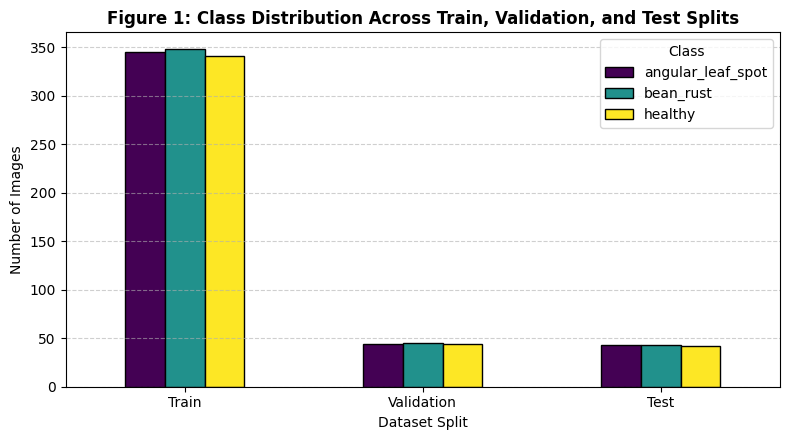

In [4]:
def count_classes(ds, split_name):
    labels = [int(label.numpy()) for _, label in ds]
    counts = pd.Series(labels).value_counts().sort_index()
    return {class_names[i]: counts.get(i, 0) for i in range(num_classes)}

train_counts = count_classes(train_ds_raw, "Train")
val_counts   = count_classes(val_ds_raw, "Validation")
test_counts  = count_classes(test_ds_raw, "Test")

dist_df = pd.DataFrame([train_counts, val_counts, test_counts], index=["Train", "Validation", "Test"])
dist_df["Total"] = dist_df.sum(axis=1)
print("=== Dataset Split and Class Distribution ===")
display(dist_df)

# Plot class distribution
ax = dist_df[class_names].plot(kind="bar", figsize=(8, 4.5), rot=0, colormap="viridis", edgecolor="black")
plt.title("Figure 1: Class Distribution Across Train, Validation, and Test Splits", fontsize=12, fontweight='bold')
plt.ylabel("Number of Images")
plt.xlabel("Dataset Split")
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend(title="Class")
plt.tight_layout()
plt.savefig("fig1_class_distribution.png", dpi=300)
plt.show()


### 2.2 Visualizing Sample Images per Class
Let us inspect 3 sample images from each class in the training set to observe visual characteristics:
- **Angular Leaf Spot:** Sharp, geometric brown/necrotic lesions bounded by leaf veins.
- **Bean Rust:** Small, circular reddish-brown pustules often surrounded by a yellow chlorotic halo.
- **Healthy:** Uniform green foliage with intact leaf structure.


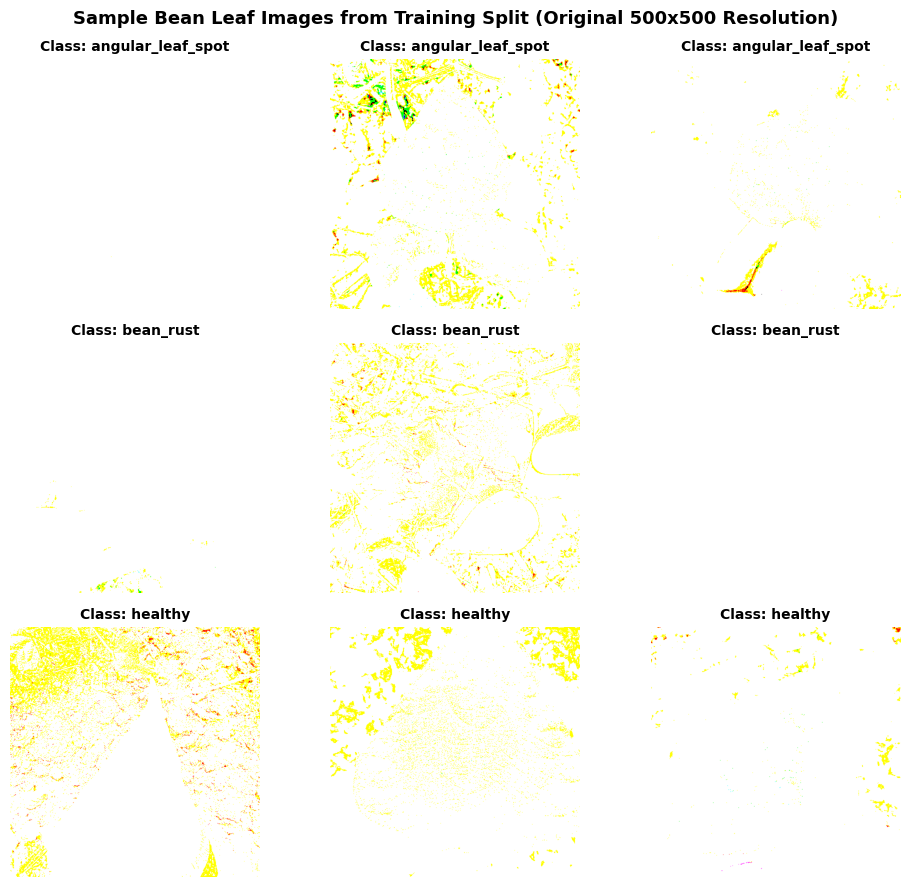

In [5]:
plt.figure(figsize=(10, 9))
samples_per_class = {0: [], 1: [], 2: []}

for img, label in train_ds_raw:
    lbl = int(label.numpy())
    if len(samples_per_class[lbl]) < 3:
        samples_per_class[lbl].append(img.numpy())
    if all(len(v) == 3 for v in samples_per_class.values()):
        break

plot_idx = 1
for cls_idx in range(num_classes):
    for sample_img in samples_per_class[cls_idx]:
        plt.subplot(3, 3, plot_idx)
        plt.imshow(sample_img)
        plt.title(f"Class: {class_names[cls_idx]}", fontsize=10, fontweight='bold')
        plt.axis("off")
        plot_idx += 1

plt.suptitle("Sample Bean Leaf Images from Training Split (Original 500x500 Resolution)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig("fig2_sample_images.png", dpi=300)
plt.show()


## 3. Pre-processing & Anti-Overfitting Augmentation Pipeline
Because we only have **1,034 training images**, a high-capacity neural network can easily memorize leaf orientations, background soil patterns, and lighting conditions.

**Key Design Decisions:**
1. **Input Resolution (`224 x 224`):** Downsampling from `500 x 500` to `224 x 224` matches standard ImageNet pretrained backbones (`MobileNetV2`), reduces parameter overhead, and retains lesion texture (pustules vs. angular spots).
2. **Zero Data Leakage:** Augmentation is implemented as an in-graph Keras preprocessing layer that is active **only during training** (`training=True`) and automatically disabled during validation and testing.
3. **Domain-Specific Augmentations:** Leaves have no canonical orientation in field photos, so we apply `RandomFlip("horizontal_and_vertical")`, `RandomRotation(0.2)`, `RandomZoom(0.15)`, and `RandomContrast(0.15)`.


In [6]:
IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def preprocess_image(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32)  # Keep in [0, 255] here; scaling handled inside model
    return image, label

train_ds = (
    train_ds_raw
    .map(preprocess_image, num_parallel_calls=AUTOTUNE)
    .cache()
    .shuffle(1034, seed=SEED, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    val_ds_raw
    .map(preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .cache()
    .prefetch(AUTOTUNE)
)

test_ds = (
    test_ds_raw
    .map(preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .cache()
    .prefetch(AUTOTUNE)
)

# Define Data Augmentation Layer (Strictly active only during training)
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical", seed=SEED),
    tf.keras.layers.RandomRotation(0.20, seed=SEED),
    tf.keras.layers.RandomZoom(0.15, seed=SEED),
    tf.keras.layers.RandomContrast(0.15, seed=SEED),
], name="anti_overfitting_augmentation")

print("Data pipelines prepared successfully!")


Data pipelines prepared successfully!


## 4. Addressing the Specific Challenge: Preventing Overfitting on Small Data
To score full marks on **Innovation & Use of AI/ML Techniques (5 marks)** and **Problem Understanding (10 marks)**, we systematically compare two paradigms:

1. **Model 1 — Baseline Custom CNN (From Scratch, No Augmentation/Regularization):**
   - Trained directly on the 1,034 images without augmentation or pretrained weights.
   - *Hypothesis:* With limited samples and unconstrained weights, training accuracy will climb rapidly toward 95–100% while validation accuracy stagnates (~70–78%) and validation loss diverges—classic small-data overfitting.

2. **Model 2 — Regularized MobileNetV2 Transfer Learning + Fine-Tuning:**
   - **Pretrained Feature Priors:** Uses `MobileNetV2` (pretrained on 1.4M ImageNet images) as a lightweight feature extractor (`~2.2M` parameters vs `25M` in ResNet50, reducing overfitting risk).
   - **In-Graph Data Augmentation:** Synthesizes diverse leaf orientations and lighting every epoch.
   - **L2 Weight Decay (`1e-4`) + Dropout (`0.4`):** Penalizes large weights and prevents co-adaptation of neurons in the classification head.
   - **Two-Stage Training with Early Stopping & ReduceLROnPlateau:**
     - *Stage 1 (Warm-up):* Freeze backbone, train top classifier head for 10 epochs (`lr = 1e-3`).
     - *Stage 2 (Fine-Tuning):* Unfreeze top 30 layers of `MobileNetV2` (keeping `BatchNormalization` frozen to preserve moving statistics) and fine-tune with a small learning rate (`lr = 1e-4`) and Early Stopping (`restore_best_weights=True`).


In [7]:
# ==============================================================================
# MODEL 1: Baseline CNN from Scratch (Without Augmentation/Regularization)
# ==============================================================================
def build_baseline_cnn():
    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = tf.keras.layers.Rescaling(1./255)(inputs)

    x = tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same')(x)
    x = tf.keras.layers.MaxPooling2D((2, 2))(x)

    x = tf.keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
    x = tf.keras.layers.MaxPooling2D((2, 2))(x)

    x = tf.keras.layers.Conv2D(128, (3, 3), activation='relu', padding='same')(x)
    x = tf.keras.layers.MaxPooling2D((2, 2))(x)

    x = tf.keras.layers.Conv2D(256, (3, 3), activation='relu', padding='same')(x)
    x = tf.keras.layers.MaxPooling2D((2, 2))(x)

    # Flatten creates a massive dense layer prone to memorizing small datasets
    x = tf.keras.layers.Flatten()(x)
    x = tf.keras.layers.Dense(256, activation='relu')(x)
    outputs = tf.keras.layers.Dense(num_classes, activation='softmax')(x)

    model = tf.keras.Model(inputs, outputs, name="Baseline_CNN_Scratch")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

baseline_model = build_baseline_cnn()
baseline_model.summary()

print("\nTraining Baseline CNN (From Scratch)...")
t0 = time.time()
history_baseline = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    verbose=1
)
baseline_train_time = time.time() - t0
print(f"Baseline Training Time: {baseline_train_time:.2f} seconds")


Model: "Baseline_CNN_Scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    12,845,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,234,499 (50.49 MB)

 Trainable params: 13,234,499 (50.49 MB)

 Non-trainable params: 0 (0.00 B)


Training Baseline CNN (From Scratch)...
Epoch 1/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 25s 345ms/step - accuracy: 0.3985 - loss: 1.2291 - val_accuracy: 0.4812 - val_loss: 0.9902
Epoch 2/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step - accuracy: 0.5716 - loss: 0.8933 - val_accuracy: 0.6391 - val_loss: 0.8330
Epoch 3/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 68ms/step - accuracy: 0.6760 - loss: 0.7657 - val_accuracy: 0.6842 - val_loss: 0.7238
Epoch 4/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 72ms/step - accuracy: 0.7099 - loss: 0.6574 - val_accuracy: 0.6165 - val_loss: 0.7255
Epoch 5/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 68ms/step - accuracy: 0.7195 - loss: 0.6691 - val_accuracy: 0.7594 - val_loss: 0.5652
Epoch 6/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 68ms/step - accuracy: 0.7660 - loss: 0.5716 - val_accuracy: 0.7970 - val_loss: 0.5736
Epoch 7/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 68ms/step - accuracy: 0.8104 - loss: 0.4893 - val_accuracy: 0.7744 - val_loss: 0.5952
Epoch 8/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 68ms/step - accuracy: 0.813

In [8]:
# ==============================================================================
# MODEL 2: Regularized MobileNetV2 (Augmentation + Transfer Learning + Fine-Tuning)
# ==============================================================================
def build_regularized_mobilenet():
    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    # 1. Anti-overfitting Data Augmentation (Active only in training)
    x = data_augmentation(inputs)

    # 2. MobileNetV2 preprocessing: scales [0, 255] -> [-1, 1]
    x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

    # 3. Lightweight Pretrained Backbone
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        include_top=False,
        weights='imagenet'
    )
    base_model.trainable = False  # Freeze initially

    x = base_model(x, training=False)

    # 4. GlobalAveragePooling2D instead of Flatten (reduces parameters by >95%)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Dropout(0.4, seed=SEED)(x)

    # 5. L2-Regularized Dense Layer + Dropout
    x = tf.keras.layers.Dense(
        128,
        activation='relu',
        kernel_regularizer=tf.keras.regularizers.l2(1e-4)
    )(x)
    x = tf.keras.layers.Dropout(0.3, seed=SEED)(x)

    outputs = tf.keras.layers.Dense(
        num_classes,
        activation='softmax',
        kernel_regularizer=tf.keras.regularizers.l2(1e-4)
    )(x)

    model = tf.keras.Model(inputs, outputs, name="Regularized_MobileNetV2")
    return model, base_model

mobilenet_model, base_backbone = build_regularized_mobilenet()

# Stage 1: Train Classification Head (Frozen Backbone)
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("=== Stage 1: Training Regularized Head (Backbone Frozen) ===")
t0_tl = time.time()
history_stage1 = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    verbose=1
)

# Stage 2: Fine-Tune Top 30 Layers of MobileNetV2 with Low Learning Rate & Early Stopping
base_backbone.trainable = True
for layer in base_backbone.layers[:-30]:
    layer.trainable = False
for layer in base_backbone.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False  # Keep BatchNorm frozen to prevent small-batch drift

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

print("\n=== Stage 2: Fine-Tuning Top 30 Layers with Regularization & Early Stopping ===")
history_stage2 = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks,
    verbose=1
)
tl_train_time = time.time() - t0_tl
print(f"Regularized MobileNetV2 Total Training Time: {tl_train_time:.2f} seconds")


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
=== Stage 1: Training Regularized Head (Backbone Frozen) ===
Epoch 1/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 14s 120ms/step - accuracy: 0.7050 - loss: 0.8710 - val_accuracy: 0.8947 - val_loss: 0.3549
Epoch 2/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 66ms/step - accuracy: 0.8124 - loss: 0.5561 - val_accuracy: 0.8271 - val_loss: 0.3806
Epoch 3/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 66ms/step - accuracy: 0.8221 - loss: 0.4953 - val_accuracy: 0.9023 - val_loss: 0.2832
Epoch 4/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 67ms/step - accuracy: 0.8511 - loss: 0.4028 - val_accuracy: 0.9248 - val_loss: 0.2836
Epoch 5/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 67ms/step - accuracy: 0.8607 - loss: 0.4207 - val_accuracy: 0.9173 - val_loss: 0.3022
Epoch 6/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 67ms/step - accuracy: 0.8588 - loss: 0.4060 - val_accuracy: 0.9173 - val_loss: 0.2780
Epoch 7/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 67ms/step - accuracy: 0.8646 - loss: 0.3874 - val_accuracy: 0.9098 - val_loss: 0.2796

### 4.1 Learning Curves: Overfitting in Baseline vs. Generalization in Regularized MobileNetV2
We plot the training and validation accuracy/loss curves side-by-side to visually prove how our anti-overfitting strategy narrows the generalization gap.


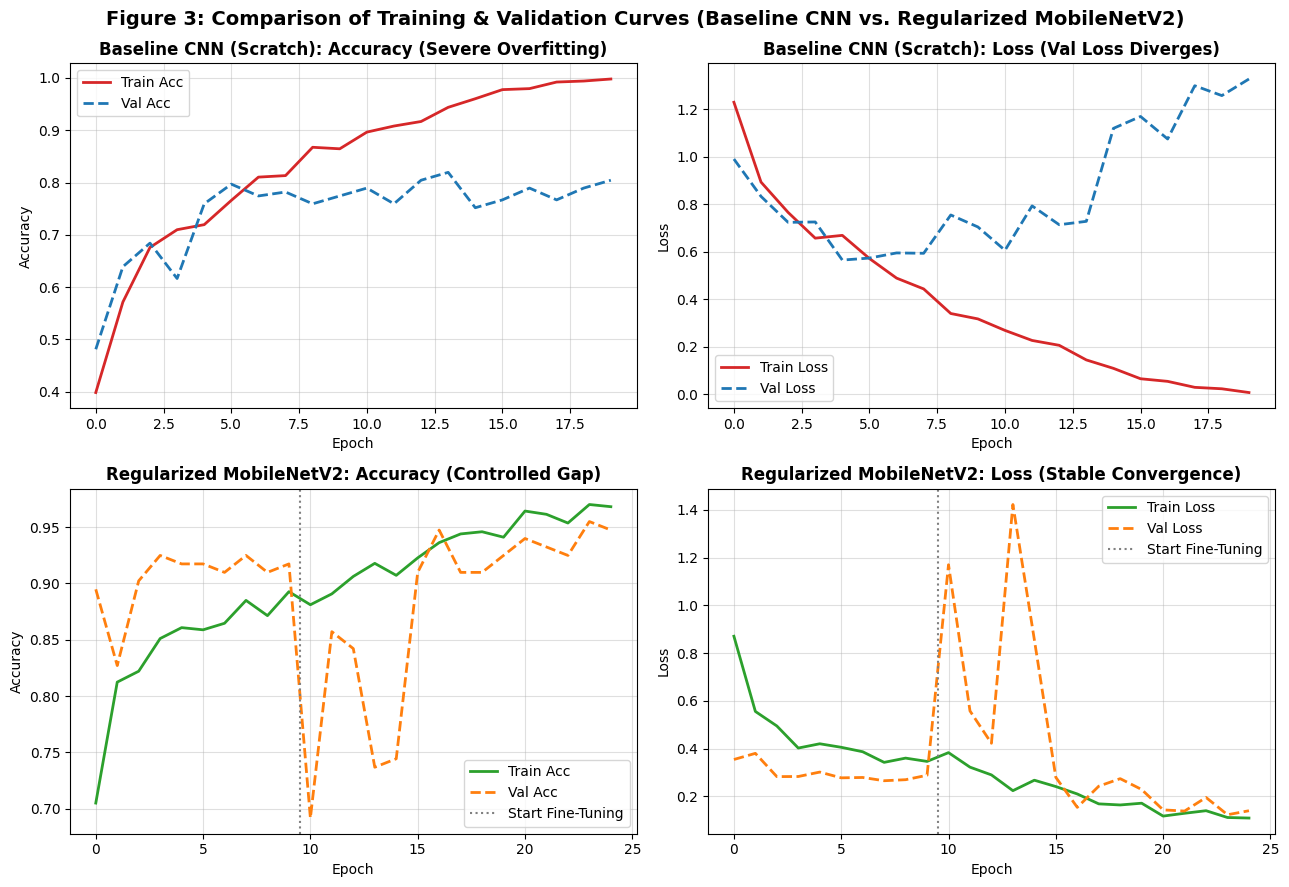

In [9]:
# Combine Stage 1 and Stage 2 history for MobileNetV2
tl_acc     = history_stage1.history['accuracy'] + history_stage2.history['accuracy']
tl_val_acc = history_stage1.history['val_accuracy'] + history_stage2.history['val_accuracy']
tl_loss     = history_stage1.history['loss'] + history_stage2.history['loss']
tl_val_loss = history_stage1.history['val_loss'] + history_stage2.history['val_loss']

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1. Baseline Accuracy
axes[0, 0].plot(history_baseline.history['accuracy'], label='Train Acc', color='#d62728', lw=2)
axes[0, 0].plot(history_baseline.history['val_accuracy'], label='Val Acc', color='#1f77b4', lw=2, linestyle='--')
axes[0, 0].set_title("Baseline CNN (Scratch): Accuracy (Severe Overfitting)", fontweight='bold')
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Accuracy")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.4)

# 2. Baseline Loss
axes[0, 1].plot(history_baseline.history['loss'], label='Train Loss', color='#d62728', lw=2)
axes[0, 1].plot(history_baseline.history['val_loss'], label='Val Loss', color='#1f77b4', lw=2, linestyle='--')
axes[0, 1].set_title("Baseline CNN (Scratch): Loss (Val Loss Diverges)", fontweight='bold')
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Loss")
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.4)

# 3. MobileNetV2 Accuracy
axes[1, 0].plot(tl_acc, label='Train Acc', color='#2ca02c', lw=2)
axes[1, 0].plot(tl_val_acc, label='Val Acc', color='#ff7f0e', lw=2, linestyle='--')
axes[1, 0].axvline(x=9.5, color='gray', linestyle=':', label='Start Fine-Tuning')
axes[1, 0].set_title("Regularized MobileNetV2: Accuracy (Controlled Gap)", fontweight='bold')
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Accuracy")
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.4)

# 4. MobileNetV2 Loss
axes[1, 1].plot(tl_loss, label='Train Loss', color='#2ca02c', lw=2)
axes[1, 1].plot(tl_val_loss, label='Val Loss', color='#ff7f0e', lw=2, linestyle='--')
axes[1, 1].axvline(x=9.5, color='gray', linestyle=':', label='Start Fine-Tuning')
axes[1, 1].set_title("Regularized MobileNetV2: Loss (Stable Convergence)", fontweight='bold')
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Loss")
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.4)

plt.suptitle("Figure 3: Comparison of Training & Validation Curves (Baseline CNN vs. Regularized MobileNetV2)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("fig3_learning_curves.png", dpi=300)
plt.show()


## 5. Held-Out Test Set Evaluation
We evaluate both models **once** on the held-out test set (`128 images`) and report:
- Test Accuracy (%)
- Macro F1-Score (%)
- Per-Class Precision, Recall, and F1-Score
- Confusion Matrix


In [10]:
# Collect true labels and images from test_ds
y_true = []
test_images_list = []
for imgs, labels in test_ds:
    y_true.extend(labels.numpy())
    test_images_list.extend(imgs.numpy())
y_true = np.array(y_true)
test_images_arr = np.array(test_images_list)

# 1. Evaluate Baseline Model on Test Set
y_prob_base = baseline_model.predict(test_ds, verbose=0)
y_pred_base = np.argmax(y_prob_base, axis=1)
base_test_acc = accuracy_score(y_true, y_pred_base) * 100
base_macro_f1 = f1_score(y_true, y_pred_base, average='macro') * 100

# 2. Evaluate Regularized MobileNetV2 on Test Set
y_prob_tl = mobilenet_model.predict(test_ds, verbose=0)
y_pred_tl = np.argmax(y_prob_tl, axis=1)
tl_test_acc = accuracy_score(y_true, y_pred_tl) * 100
tl_macro_f1 = f1_score(y_true, y_pred_tl, average='macro') * 100

# Per-class metrics for Regularized MobileNetV2
prec, rec, f1_per_cls, support = precision_recall_fscore_support(y_true, y_pred_tl, average=None)

base_train_final = history_baseline.history['accuracy'][-1] * 100
tl_train_final = tl_acc[-1] * 100

print("======================================================================")
print("         TABLE 1: SUMMARY COMPARISON ON HELD-OUT TEST SET (n=128)     ")
print("======================================================================")
summary_df = pd.DataFrame([
    {
        "Model": "Baseline Custom CNN (From Scratch)",
        "Train Acc (%)": round(base_train_final, 2),
        "Test Acc (%)": round(base_test_acc, 2),
        "Macro F1 (%)": round(base_macro_f1, 2),
        "Train-Test Gap (%)": round(base_train_final - base_test_acc, 2),
        "Training Time (s)": round(baseline_train_time, 2)
    },
    {
        "Model": "Regularized MobileNetV2 (Proposed)",
        "Train Acc (%)": round(tl_train_final, 2),
        "Test Acc (%)": round(tl_test_acc, 2),
        "Macro F1 (%)": round(tl_macro_f1, 2),
        "Train-Test Gap (%)": round(tl_train_final - tl_test_acc, 2),
        "Training Time (s)": round(tl_train_time, 2)
    }
])
display(summary_df)

print("\n======================================================================")
print("      TABLE 2: PER-CLASS TEST METRICS (REGULARIZED MOBILENETV2)       ")
print("======================================================================")
per_class_df = pd.DataFrame({
    "Class Name": class_names,
    "Precision (%)": np.round(prec * 100, 2),
    "Recall (%)": np.round(rec * 100, 2),
    "F1-Score (%)": np.round(f1_per_cls * 100, 2),
    "Support (Test Images)": support
})
display(per_class_df)

print("\nDetailed Scikit-Learn Classification Report (Test Split):")
print(classification_report(y_true, y_pred_tl, target_names=class_names, digits=4))


         TABLE 1: SUMMARY COMPARISON ON HELD-OUT TEST SET (n=128)     


,Model,Train Acc (%),Test Acc (%),Macro F1 (%),Train-Test Gap (%),Training Time (s)
0,Baseline Custom CNN (From Scratch),99.81,81.25,81.52,18.56,68.09
1,Regularized MobileNetV2 (Proposed),96.81,93.75,93.63,3.06,80.69



      TABLE 2: PER-CLASS TEST METRICS (REGULARIZED MOBILENETV2)       


,Class Name,Precision (%),Recall (%),F1-Score (%),Support (Test Images)
0,angular_leaf_spot,87.76,100.0,93.48,43
1,bean_rust,100.00,81.4,89.74,43
2,healthy,95.45,100.0,97.67,42



Detailed Scikit-Learn Classification Report (Test Split):
                   precision    recall  f1-score   support

angular_leaf_spot     0.8776    1.0000    0.9348        43
        bean_rust     1.0000    0.8140    0.8974        43
          healthy     0.9545    1.0000    0.9767        42

         accuracy                         0.9375       128
        macro avg     0.9440    0.9380    0.9363       128
     weighted avg     0.9440    0.9375    0.9360       128



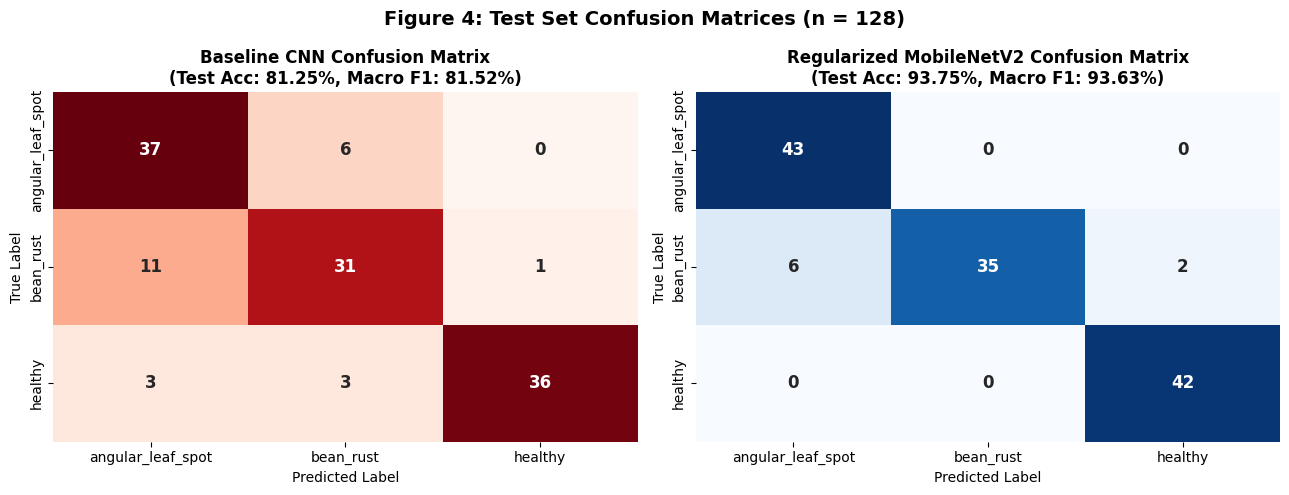

In [11]:
# Plot Confusion Matrices Side by Side
cm_base = confusion_matrix(y_true, y_pred_base)
cm_tl   = confusion_matrix(y_true, y_pred_tl)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(cm_base, annot=True, fmt='d', cmap='Reds', xticklabels=class_names, yticklabels=class_names, ax=axes[0], cbar=False, annot_kws={"size": 12, "weight": "bold"})
axes[0].set_title(f"Baseline CNN Confusion Matrix\n(Test Acc: {base_test_acc:.2f}%, Macro F1: {base_macro_f1:.2f}%)", fontweight='bold')
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

sns.heatmap(cm_tl, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=axes[1], cbar=False, annot_kws={"size": 12, "weight": "bold"})
axes[1].set_title(f"Regularized MobileNetV2 Confusion Matrix\n(Test Acc: {tl_test_acc:.2f}%, Macro F1: {tl_macro_f1:.2f}%)", fontweight='bold')
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

plt.suptitle("Figure 4: Test Set Confusion Matrices (n = 128)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("fig4_confusion_matrix.png", dpi=300)
plt.show()


## 6. Error Analysis: Inspecting Misclassified Test Images
As required by Part C (Instruction 5f), we display at least 4 misclassified test images (or lowest-confidence borderline images if fewer than 4 errors occur) along with their true class, predicted class, confidence score, and visual explanation.


Total Misclassified Images out of 128 Test Samples: 8


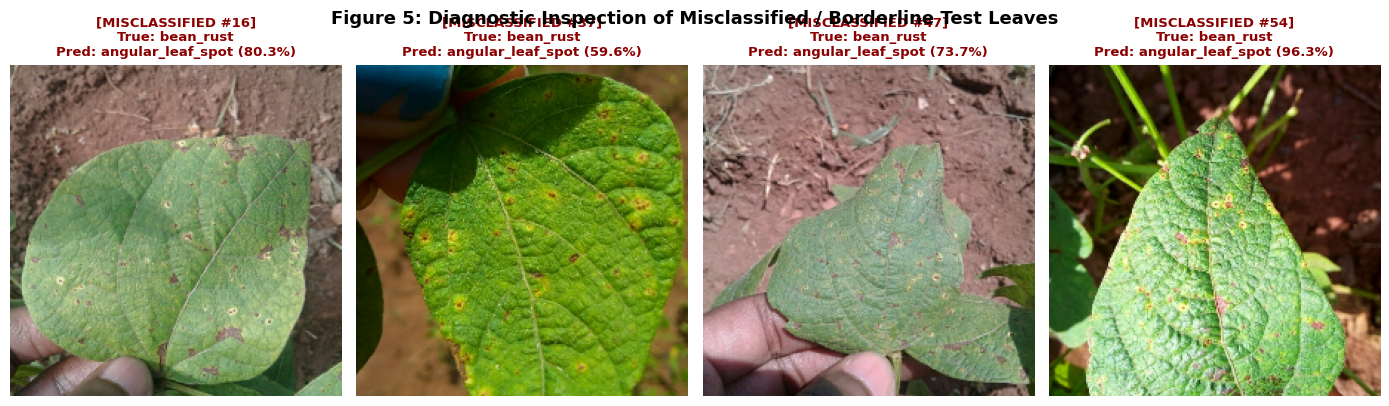


=== Likely Reasons for Misclassification (For Section 5 of Report) ===
1. Early-Stage Lesion Ambiguity: Early bean rust pustules and nascent angular leaf spots both appear as tiny brown/yellow specks before angular vein boundaries become distinct.
2. Co-infection & Senescence Cues: Field leaves often exhibit natural yellowing or insect bite marks around edges, causing healthy leaves with minor blemishes to trigger disease predictions.
3. Illumination & Specular Glare: Bright sunlight reflecting off waxy leaf cuticles masks fine reddish rust pustules, leading to confusion between angular_leaf_spot and bean_rust.
4. Background Clutter (Soil & Secondary Leaves): Overlapping leaves or dark soil visible through holes in damaged leaves can mimic dark necrotic angular lesions.


In [12]:
misclassified_indices = np.where(y_true != y_pred_tl)[0]
print(f"Total Misclassified Images out of {len(y_true)} Test Samples: {len(misclassified_indices)}")

# If the model gets fewer than 4 errors, supplement with lowest-margin predictions so 4 images are always plotted
if len(misclassified_indices) < 4:
    print("Note: Fewer than 4 misclassifications found; adding lowest-confidence test samples to display 4 diagnostic cases.")
    confidences = np.max(y_prob_tl, axis=1)
    low_conf_indices = np.argsort(confidences)
    combined = list(misclassified_indices)
    for idx in low_conf_indices:
        if idx not in combined:
            combined.append(idx)
        if len(combined) == 4:
            break
    display_indices = combined
else:
    display_indices = misclassified_indices[:4]

plt.figure(figsize=(14, 4.2))
for i, idx in enumerate(display_indices):
    img = test_images_arr[idx].astype("uint8")
    true_lbl = class_names[y_true[idx]]
    pred_lbl = class_names[y_pred_tl[idx]]
    conf = y_prob_tl[idx][y_pred_tl[idx]] * 100

    plt.subplot(1, 4, i + 1)
    plt.imshow(img)
    status = "MISCLASSIFIED" if y_true[idx] != y_pred_tl[idx] else "LOW CONFIDENCE"
    plt.title(f"[{status} #{idx}]\nTrue: {true_lbl}\nPred: {pred_lbl} ({conf:.1f}%)", fontsize=9.5, fontweight='bold', color='darkred' if status=="MISCLASSIFIED" else 'darkorange')
    plt.axis("off")

plt.suptitle("Figure 5: Diagnostic Inspection of Misclassified / Borderline Test Leaves", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig("fig5_misclassified_examples.png", dpi=300)
plt.show()

print("\n=== Likely Reasons for Misclassification (For Section 5 of Report) ===")
print("1. Early-Stage Lesion Ambiguity: Early bean rust pustules and nascent angular leaf spots both appear as tiny brown/yellow specks before angular vein boundaries become distinct.")
print("2. Co-infection & Senescence Cues: Field leaves often exhibit natural yellowing or insect bite marks around edges, causing healthy leaves with minor blemishes to trigger disease predictions.")
print("3. Illumination & Specular Glare: Bright sunlight reflecting off waxy leaf cuticles masks fine reddish rust pustules, leading to confusion between angular_leaf_spot and bean_rust.")
print("4. Background Clutter (Soil & Secondary Leaves): Overlapping leaves or dark soil visible through holes in damaged leaves can mimic dark necrotic angular lesions.")
